In [1]:
%pip install pandas numpy matplotlib scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
   -- ------------------------------------- 0.8/10.7 MB 2.0 MB/s eta 0:00:05
   --- ------------------------------------ 1.0/10.7 MB 2.0 MB/s eta 0:00:05
   ------ --------------------------------- 1.8/10.7 MB 2.3 MB/s eta 0:00:04
   ------- -------------------------------- 2.1/10.7 MB 2.1 MB/s eta 0:00:05
   -------- ------------------------------- 2.4/10.7 MB 2.0 MB/s eta 0:00:05
   ---------- ----------------------------- 2.9/10.7 MB 2.1 MB/s eta 0:00:04
   ------------- -------------------------- 3.7/10.7 MB 2.2 MB/s eta 0:00:04
   --------------- ------------------------ 4.2/10.7 MB 2.2 MB/s eta 0:00:03
   ---------------- ----------------------- 4.5/10.7 MB 2.3 MB/s eta 0:00:03
   ----------------- ----


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\Himanshu\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    average_precision_score
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
N_STUDENTS = 40
SECONDS_PER_STUDENT = 180

video_parts = []
event_parts = []
label_parts = []

start_time = pd.Timestamp("2026-01-01 09:00:00")

# Spread positive examples across students so both
# training and test groups can contain positive labels.
positive_students = {
    3, 7, 11, 15, 19, 23, 27, 31, 35, 39
}

for student_num in range(N_STUDENTS):

    student_id = f"S{student_num + 1:03d}"

    timestamps = pd.date_range(
        start=start_time + pd.Timedelta(minutes=student_num * 5),
        periods=SECONDS_PER_STUDENT,
        freq="s"
    )

    t = np.arange(SECONDS_PER_STUDENT)

    gaze_x = rng.normal(0, 0.22, SECONDS_PER_STUDENT)
    gaze_y = rng.normal(0, 0.18, SECONDS_PER_STUDENT)
    head_yaw = rng.normal(0, 8, SECONDS_PER_STUDENT)
    audio_level = np.abs(
        rng.normal(0.12, 0.07, SECONDS_PER_STUDENT)
    )

    suspicious = np.zeros(SECONDS_PER_STUDENT, dtype=int)

    if student_num in positive_students:

        segment_start = 50
        segment_end = 85

        gaze_x[segment_start:segment_end] += 0.9
        head_yaw[segment_start:segment_end] += 30
        audio_level[segment_start:segment_end] += 0.2

        suspicious[segment_start:segment_end] = 1

    video_parts.append(pd.DataFrame({
        "student_id": student_id,
        "timestamp": timestamps,
        "gaze_x": gaze_x,
        "gaze_y": gaze_y,
        "head_yaw": head_yaw,
        "audio_level": audio_level
    }))

    label_parts.append(pd.DataFrame({
        "student_id": student_id,
        "timestamp": timestamps,
        "suspicious": suspicious
    }))

    for second in range(SECONDS_PER_STUDENT):

        if rng.random() < 0.04:
            event_parts.append({
                "student_id": student_id,
                "timestamp": timestamps[second]
                    + pd.Timedelta(milliseconds=300),
                "event_type": "tab_switch",
                "event_value": 1
            })

        if rng.random() < 0.01:
            event_parts.append({
                "student_id": student_id,
                "timestamp": timestamps[second]
                    + pd.Timedelta(milliseconds=500),
                "event_type": "copy_paste",
                "event_value": 1
            })

video = pd.concat(video_parts, ignore_index=True)
events = pd.DataFrame(event_parts)
labels = pd.concat(label_parts, ignore_index=True)

print("Video records:", len(video))
print("System events:", len(events))
print("Positive synthetic labels:", labels["suspicious"].sum())

display(video.head())
display(events.head())

Video records: 7200
System events: 370
Positive synthetic labels: 350


,student_id,timestamp,gaze_x,gaze_y,head_yaw,audio_level
0,S001,2026-01-01 09:00:00,0.067038,0.235080,-1.220180,0.001947
1,S001,2026-01-01 09:00:01,-0.228797,0.039489,3.067151,0.062164
2,S001,2026-01-01 09:00:02,0.165099,-0.073967,7.998594,0.137337
3,S001,2026-01-01 09:00:03,0.206924,0.199132,-8.468289,0.107454
4,S001,2026-01-01 09:00:04,-0.429228,0.077176,-1.000072,0.102264


,student_id,timestamp,event_type,event_value
0,S001,2026-01-01 09:00:07.500,copy_paste,1
1,S001,2026-01-01 09:00:12.300,tab_switch,1
2,S001,2026-01-01 09:00:22.300,tab_switch,1
3,S001,2026-01-01 09:00:23.300,tab_switch,1
4,S001,2026-01-01 09:00:30.300,tab_switch,1


Missing values before cleaning:


gaze_x         665
gaze_y         665
head_yaw       665
audio_level    665
dtype: int64

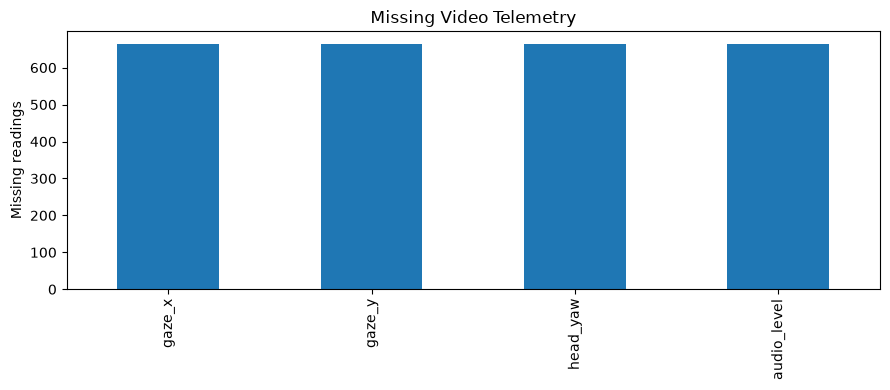

In [4]:
sensor_cols = [
    "gaze_x",
    "gaze_y",
    "head_yaw",
    "audio_level"
]

for student_id, group in video.groupby("student_id"):

    indices = group.index.to_numpy()

    # Random missing sensor readings
    missing_indices = rng.choice(
        indices,
        size=12,
        replace=False
    )

    video.loc[missing_indices, sensor_cols] = np.nan

    # Simulate a continuous connection dropout
    video.loc[indices[20:25], sensor_cols] = np.nan

print("Missing values before cleaning:")
display(video[sensor_cols].isna().sum())

plt.figure(figsize=(9, 4))
video[sensor_cols].isna().sum().plot(kind="bar")
plt.title("Missing Video Telemetry")
plt.ylabel("Missing readings")
plt.tight_layout()
plt.show()

In [5]:
video["timestamp"] = pd.to_datetime(video["timestamp"])
events["timestamp"] = pd.to_datetime(events["timestamp"])
labels["timestamp"] = pd.to_datetime(labels["timestamp"])

video = video.sort_values(
    ["student_id", "timestamp"]
).reset_index(drop=True)

video[sensor_cols] = (
    video.groupby("student_id")[sensor_cols]
    .transform(
        lambda group: group.interpolate(
            method="linear",
            limit_direction="both"
        )
    )
)

video[sensor_cols] = (
    video.groupby("student_id")[sensor_cols]
    .transform(lambda group: group.ffill().bfill())
)

print("Missing values after interpolation:")
display(video[sensor_cols].isna().sum())

print("Video rows preserved:", len(video))

Missing values after interpolation:


gaze_x         0
gaze_y         0
head_yaw       0
audio_level    0
dtype: int64

Video rows preserved: 7200


In [6]:
events["timestamp"] = events["timestamp"].dt.floor("s")

events["tab_switch_event"] = (
    events["event_type"] == "tab_switch"
).astype(int)

events["copy_paste_event"] = (
    events["event_type"] == "copy_paste"
).astype(int)

event_features = (
    events.groupby(
        ["student_id", "timestamp"],
        as_index=False
    )
    .agg(
        tab_switch_event=("tab_switch_event", "sum"),
        copy_paste_event=("copy_paste_event", "sum")
    )
)

video_sorted = video.sort_values(
    ["timestamp", "student_id"]
).reset_index(drop=True)

events_sorted = event_features.sort_values(
    ["timestamp", "student_id"]
).reset_index(drop=True)

merged = pd.merge_asof(
    video_sorted,
    events_sorted,
    on="timestamp",
    by="student_id",
    direction="nearest",
    tolerance=pd.Timedelta(seconds=1)
)

for col in ["tab_switch_event", "copy_paste_event"]:
    merged[col] = merged[col].fillna(0)

print("Merged dataset shape:", merged.shape)
display(merged.head())

Merged dataset shape: (7200, 8)


,student_id,timestamp,gaze_x,gaze_y,head_yaw,audio_level,tab_switch_event,copy_paste_event
0,S001,2026-01-01 09:00:00,0.067038,0.235080,-1.220180,0.001947,0.0,0.0
1,S001,2026-01-01 09:00:01,-0.228797,0.039489,3.067151,0.062164,0.0,0.0
2,S001,2026-01-01 09:00:02,0.165099,-0.073967,7.998594,0.137337,0.0,0.0
3,S001,2026-01-01 09:00:03,0.206924,0.199132,-8.468289,0.107454,0.0,0.0
4,S001,2026-01-01 09:00:04,-0.429228,0.077176,-1.000072,0.102264,0.0,0.0


In [7]:
merged = merged.sort_values(
    ["student_id", "timestamp"]
).reset_index(drop=True)

merged["gaze_magnitude"] = np.sqrt(
    merged["gaze_x"] ** 2 +
    merged["gaze_y"] ** 2
)

rolling_columns = [
    "gaze_x",
    "gaze_y",
    "gaze_magnitude",
    "head_yaw",
    "audio_level"
]

for col in rolling_columns:

    merged[f"{col}_roll10"] = (
        merged.groupby("student_id")[col]
        .transform(
            lambda x: x.rolling(
                window=10,
                min_periods=1
            ).mean()
        )
    )

for col in ["tab_switch_event", "copy_paste_event"]:

    merged[f"{col}_sum10"] = (
        merged.groupby("student_id")[col]
        .transform(
            lambda x: x.rolling(
                window=10,
                min_periods=1
            ).sum()
        )
    )

print("Rolling features created.")

display(merged.head())

Rolling features created.


,student_id,timestamp,gaze_x,gaze_y,head_yaw,audio_level,tab_switch_event,copy_paste_event,gaze_magnitude,gaze_x_roll10,gaze_y_roll10,gaze_magnitude_roll10,head_yaw_roll10,audio_level_roll10,tab_switch_event_sum10,copy_paste_event_sum10
0,S001,2026-01-01 09:00:00,0.067038,0.235080,-1.220180,0.001947,0.0,0.0,0.244452,0.067038,0.235080,0.244452,-1.220180,0.001947,0.0,0.0
1,S001,2026-01-01 09:00:01,-0.228797,0.039489,3.067151,0.062164,0.0,0.0,0.232179,-0.080879,0.137285,0.238316,0.923485,0.032056,0.0,0.0
2,S001,2026-01-01 09:00:02,0.165099,-0.073967,7.998594,0.137337,0.0,0.0,0.180911,0.001114,0.066867,0.219181,3.281855,0.067149,0.0,0.0
3,S001,2026-01-01 09:00:03,0.206924,0.199132,-8.468289,0.107454,0.0,0.0,0.287178,0.052566,0.099934,0.236180,0.344319,0.077225,0.0,0.0
4,S001,2026-01-01 09:00:04,-0.429228,0.077176,-1.000072,0.102264,0.0,0.0,0.436111,-0.043793,0.095382,0.276166,0.075441,0.082233,0.0,0.0


In [8]:
data = merged.merge(
    labels,
    on=["student_id", "timestamp"],
    how="inner",
    validate="one_to_one"
)

print("Class distribution:")
display(data["suspicious"].value_counts())

print(
    "Positive label percentage:",
    round(data["suspicious"].mean() * 100, 2),
    "%"
)

Class distribution:


suspicious
0    6850
1     350
Name: count, dtype: int64

Positive label percentage: 4.86 %


In [9]:
student_ids = data["student_id"].unique()

rng_split = np.random.default_rng(RANDOM_STATE)
rng_split.shuffle(student_ids)

test_students = set(student_ids[:10])

train_data = data[
    ~data["student_id"].isin(test_students)
].copy()

test_data = data[
    data["student_id"].isin(test_students)
].copy()

features = [
    "gaze_x_roll10",
    "gaze_y_roll10",
    "gaze_magnitude_roll10",
    "head_yaw_roll10",
    "audio_level_roll10",
    "tab_switch_event_sum10",
    "copy_paste_event_sum10"
]

X_train = train_data[features].fillna(0)
y_train = train_data["suspicious"]

X_test = test_data[features].fillna(0)
y_test = test_data["suspicious"]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("Training positive cases:", int(y_train.sum()))
print("Testing positive cases:", int(y_test.sum()))

Training rows: 5400
Testing rows: 1800
Training positive cases: 280
Testing positive cases: 70


C:\Users\Himanshu\AppData\Local\Temp\ipykernel_12552\3261567713.py:4: UserWarning: you are shuffling a 'StringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng_split.shuffle(student_ids)


In [10]:
model = RandomForestClassifier(
    n_estimators=250,
    class_weight="balanced",
    min_samples_leaf=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [11]:
positive_class_index = list(model.classes_).index(1)

probabilities = model.predict_proba(
    X_test
)[:, positive_class_index]

THRESHOLD = 0.90

y_pred = (
    probabilities >= THRESHOLD
).astype(int)

print("Decision threshold:", THRESHOLD)
print("Number of flagged rows:", int(y_pred.sum()))

Decision threshold: 0.9
Number of flagged rows: 56


In [12]:
precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

cm = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 score:", round(f1, 4))

print("\nConfusion matrix:")
print(cm)

print("\nFalse positives:", fp)
print("False negatives:", fn)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Suspicious"],
    zero_division=0
))

Precision: 0.9286
Recall: 0.7429
F1 score: 0.8254

Confusion matrix:
[[1726    4]
 [  18   52]]

False positives: 4
False negatives: 18

Classification report:
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      1730
  Suspicious       0.93      0.74      0.83        70

    accuracy                           0.99      1800
   macro avg       0.96      0.87      0.91      1800
weighted avg       0.99      0.99      0.99      1800



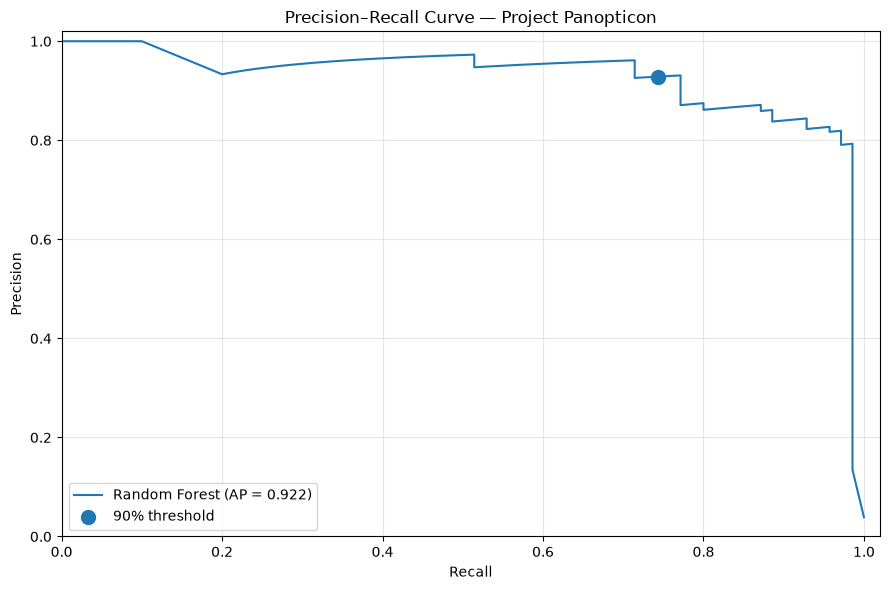

Average precision: 0.9218


In [13]:
if y_test.nunique() == 2:

    pr_precision, pr_recall, pr_thresholds = (
        precision_recall_curve(
            y_test,
            probabilities
        )
    )

    ap = average_precision_score(
        y_test,
        probabilities
    )

    plt.figure(figsize=(9, 6))

    plt.plot(
        pr_recall,
        pr_precision,
        label=f"Random Forest (AP = {ap:.3f})"
    )

    plt.scatter(
        recall,
        precision,
        s=100,
        label="90% threshold"
    )

    plt.xlabel("Recall")
    plt.ylabel("Precision")

    plt.title(
        "Precision–Recall Curve — Project Panopticon"
    )

    plt.xlim(0, 1.02)
    plt.ylim(0, 1.02)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("Average precision:", round(ap, 4))

else:
    print(
        "The test set needs both classes to plot "
        "a Precision–Recall curve."
    )

In [14]:
print("=" * 55)
print("PROJECT PANOPTICON: EXECUTIVE SUMMARY")
print("=" * 55)

print("Data source: Synthetic demonstration data")
print("Video rows preserved:", len(video))
print("System event records:", len(events))
print("Model: Class-weighted Random Forest")
print("Decision threshold:", f"{THRESHOLD:.0%}")

print("Precision:", f"{precision:.2%}")
print("Recall:", f"{recall:.2%}")
print("F1 score:", f"{f1:.2%}")

print("False positives:", fp)
print("False negatives:", fn)

print("\nBusiness interpretation:")
print(
    "Only rows with model probability >= 90% "
    "receive a suspicious flag."
)

print(
    "A high threshold can reduce false positives "
    "but may miss genuine suspicious cases."
)

print(
    "These metrics are illustrative because the "
    "dataset is synthetic."
)

print(
    "No automated flag should be treated as proof "
    "of cheating without human review."
)

PROJECT PANOPTICON: EXECUTIVE SUMMARY
Data source: Synthetic demonstration data
Video rows preserved: 7200
System event records: 370
Model: Class-weighted Random Forest
Decision threshold: 90%
Precision: 92.86%
Recall: 74.29%
F1 score: 82.54%
False positives: 4
False negatives: 18

Business interpretation:
Only rows with model probability >= 90% receive a suspicious flag.
A high threshold can reduce false positives but may miss genuine suspicious cases.
These metrics are illustrative because the dataset is synthetic.
No automated flag should be treated as proof of cheating without human review.
